In [1]:
import pandas as pd
import numpy as np
import re
import nltk
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.metrics import silhouette_score

nltk.download('stopwords')
from nltk.corpus import stopwords

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\siddi\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [ ]:
df = pd.read_json("data_503986.json")  # or .csv depending on download

print(df.head())
print(df.shape)

                    id                                               text
0  1596647314030231552  @DonutOperator @elonmusk @stillgray It's fiery...
1  1596647313887346689  @SenMarkey @elonmusk Anti-freedom is anti-Amer...
2  1596647313719853056  @FoxNews Elon Musk voices support for Trump ri...
3  1596647313346215941  @elonmusk @CollinRugg Having meetings about me...
4  1596647312746754048  @GregA06555436 @elonmusk @TimRunsHisMouth Yes!...
(503986, 2)


In [35]:
df = df.sample(50000, random_state=42).reset_index(drop=True)

print("Sample size:", df.shape)

Sample size: (50000, 2)


In [36]:
stop_words = set(stopwords.words('english'))

def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+", "", text)          # remove URLs
    text = re.sub(r"@\w+", "", text)             # remove mentions
    text = re.sub(r"#\w+", "", text)             # remove hashtags
    text = re.sub(r"[^a-z\s]", "", text)         # remove punctuation
    text = " ".join([w for w in text.split() if w not in stop_words])
    return text

df['clean_text'] = df['text'].apply(clean_text)

df.head()

,id,text,clean_text
0,1603474811308613632,"@BR00KLYFN_ Hello, @TwitterSupport @Twitter @e...",hello user evading permanent suspension suspen...
1,1603936647644602369,@elonmusk can we fedpost on here now ?,fedpost
2,1598328975327399936,@elonmusk One mtg with Apple and everything is...,one mtg apple everything okidoki
3,1604592249001881600,@Victorshi2020 @elonmusk Who’s we??,whos
4,1605727165412265985,@nlyonne LMAO i love you. just follow her @elo...,lmao love follow


In [37]:
vectorizer = TfidfVectorizer(max_features=5000)
X = vectorizer.fit_transform(df['clean_text'])

print(X.shape)

(50000, 5000)


In [38]:
k = 3  # assume: positive, negative, neutral

kmeans = KMeans(n_clusters=k, random_state=42)
clusters = kmeans.fit_predict(X)

df['sentiment_cluster'] = clusters

In [39]:
score = silhouette_score(X, clusters)
print("Silhouette Score:", score)

Silhouette Score: 0.0083892417398601


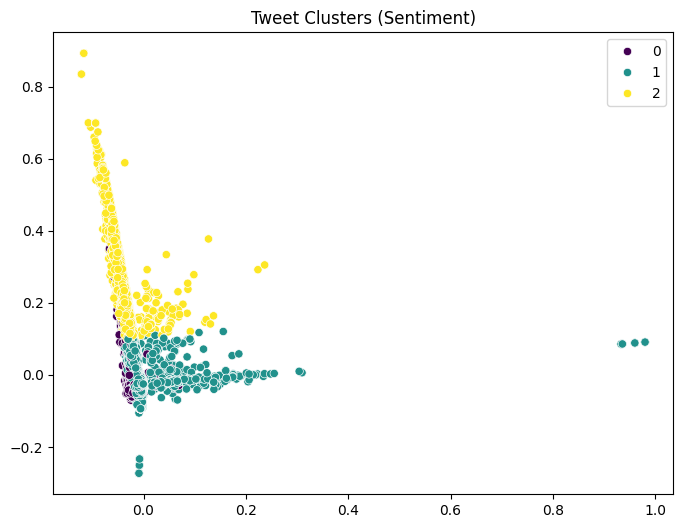

In [40]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X.toarray())

plt.figure(figsize=(8,6))
sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1], hue=clusters, palette='viridis')
plt.title("Tweet Clusters (Sentiment)")
plt.show()

In [41]:
terms = vectorizer.get_feature_names_out()

for i in range(k):
    center_terms = kmeans.cluster_centers_[i].argsort()[-10:]
    print(f"\nCluster {i} top words:")
    print([terms[ind] for ind in center_terms])


Cluster 0 top words:
['please', 'care', 'twitter', 'get', 'want', 'people', 'think', 'know', 'like', 'dont']

Cluster 1 top words:
['right', 'good', 'im', 'would', 'youre', 'get', 'one', 'people', 'like', 'twitter']

Cluster 2 top words:
['people', 'free', 'thank', 'speech', 'like', 'via', 'musks', 'twitter', 'musk', 'elon']


In [42]:
iso = IsolationForest(contamination=0.05, random_state=42)
df['spam_label'] = iso.fit_predict(X)

# Convert labels
df['spam_label'] = df['spam_label'].map({1: 'Not Spam', -1: 'Spam'})

df[['text', 'spam_label']].head()

,text,spam_label
0,"@BR00KLYFN_ Hello, @TwitterSupport @Twitter @e...",Not Spam
1,@elonmusk can we fedpost on here now ?,Not Spam
2,@elonmusk One mtg with Apple and everything is...,Not Spam
3,@Victorshi2020 @elonmusk Who’s we??,Not Spam
4,@nlyonne LMAO i love you. just follow her @elo...,Not Spam


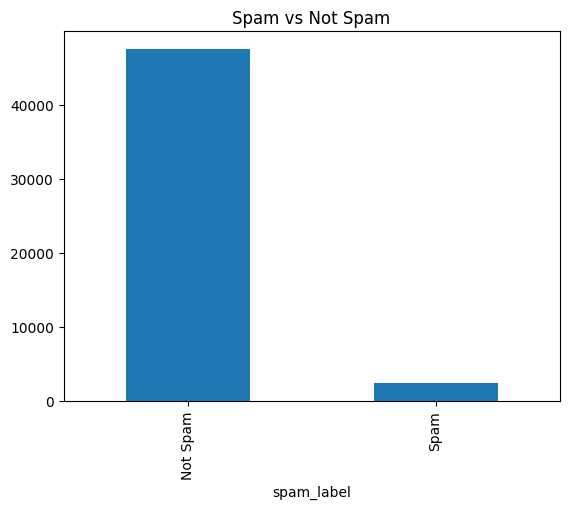

In [43]:
df['spam_label'].value_counts().plot(kind='bar')
plt.title("Spam vs Not Spam")
plt.show()

In [44]:
spam_samples = df[df['spam_label'] == 'Spam']['text'].head(10)

for i, text in enumerate(spam_samples):
    print(f"{i+1}. {text}\n")

1. @marlon22354722 @LisaLivesLoves @elonmusk STEALTH LAUNCHED TRUMPLON ON #BSC
✅LP LOCKED
✅#BUSD   rewards
✅Experienced team
✅Low starting LP
✅ NO PRESALE NO PRIVATE NO TEAM TOKENS 
✅50% burned 
#trumplon $trumplon #trump #ELONMUSK 
https://t.co/OjNwgjX3sr
https://t.co/cRnTz9fICj… # 1552 https://t.co/wlruU2O495

2. @TA4CryptoBot JOIN @FrogXmas - a project created to support disadvantaged kids, celebrate the holiday in crypto space and to profit all  investors
Prepare yourself for being part of the greatest and most rewarding Xmas token!
#BSCGem #frogxmas #presale #memecoin #100xGems  #lowcapgem #elonmusk https://t.co/s4HrnbXiQ2

3. @elonmusk I looked again today only to find that you still have not resigned. You cannot resign fast enough for sensible (majority of )Americans. You have become nothing more than a mouthpiece for the far right conspiracists. It is shameful that a "man" of your position is a political tool

4. @BeardOfDan1 @LPNH @elonmusk Who knows, delivery keeps slipping. 

In [45]:
df.to_csv("processed_tweets.csv", index=False)

🎨 What the 3 colors mean

You got 3 clusters:

🟣 Cluster 0 (purple)
Dense near the center-left
Small variation
Often contains:
neutral tweets
short replies
low-information text

👉 Interpretation: Neutral / generic tweets

🟢 Cluster 1 (teal/green)
Spread horizontally
Includes a few extreme right-side points
Likely contains:
factual/news-like tweets
structured statements
retweets or informational content

👉 Interpretation: Informational / news-like tweets

🟡 Cluster 2 (yellow)
Higher vertically
More spread upward
Often contains:
emotional language
opinionated tweets
strong reactions

👉 Interpretation: Opinionated / emotionally strong tweets (likely “positive/negative mix”)

⚠️ Important insight (VERY important for your report)

This is NOT true sentiment analysis.

It is:

🔴 “semantic grouping based on word similarity”

NOT:

❌ positive / negative labels
❌ true sentiment understanding

KMeans only groups tweets that “look similar in word usage”.

🧠 Why the shape looks like this
1. Dense center cluster

Most tweets are:

short
repetitive
generic replies

So they cluster tightly near origin.

2. Spread on edges

Outliers like:

news headlines
long tweets
emotional tweets
spam

get pushed away → appear separated.

3. PCA distortion (VERY important)

PCA compresses thousands of dimensions into 2.

So:

distances are not exact
clusters overlap visually even if they are separate in real space
🚨 What about that far-right green dots?

Those are:

👉 outlier tweets

Usually:

spam-like content
very rare vocabulary
long structured sentences

Your Isolation Forest (spam model) would likely flag some of these.

📌 How to describe this in your assignment

You can write:

The tweets were transformed into TF-IDF vectors and clustered using KMeans. PCA was used to reduce dimensionality for visualization. The resulting clusters represent groups of semantically similar tweets rather than true sentiment labels. One cluster shows tightly grouped generic tweets, while another contains more expressive or opinionated content. Outliers indicate rare or potentially spam-like tweets.